In [ ]:
import gymnasium as gym
from my_USV_Env import MyUsvEnv_Gym
# Register the environment so we can create it with gym.make()
gym.register(
    id="myenv/MyUsvEnv_Gym-v0",
    entry_point=MyUsvEnv_Gym,
)
# 2. 创建环境实例
env = gym.make("myenv/MyUsvEnv_Gym-v0")  # 使用注册的id创建环境
from gymnasium.utils.env_checker import check_env
# This will catch many common issues
try:
    check_env(env)
    print("Environment passes all checks!")
except Exception as e:
    print(f"Environment has issues: {e}")

In [5]:
from stable_baselines3 import TD3
from stable_baselines3.common.env_util import make_vec_env
# Parallel environments
vec_env = make_vec_env("myenv/MyUsvEnv_Gym-v0", n_envs=4)
model = TD3("MultiInputPolicy", vec_env, verbose=1)
model.learn(total_timesteps=250000)
model.save("td3_MyUsvEnv")

c:\Users\Administrator\miniconda3\envs\HandOnRl\lib\site-packages\gymnasium\envs\registration.py:736: UserWarning: WARN: The environment is being initialised with render_mode='rgb_array' that is not in the possible render_modes ([]).
  logger.warn(
c:\Users\Administrator\miniconda3\envs\HandOnRl\lib\site-packages\gymnasium\spaces\box.py:235: UserWarning: WARN: Box low's precision lowered by casting to float32, current low.dtype=float64
  gym.logger.warn(
c:\Users\Administrator\miniconda3\envs\HandOnRl\lib\site-packages\gymnasium\spaces\box.py:305: UserWarning: WARN: Box high's precision lowered by casting to float32, current high.dtype=float64
  gym.logger.warn(
c:\Users\Administrator\miniconda3\envs\HandOnRl\lib\site-packages\gymnasium\utils\passive_env_checker.py:134: UserWarning: WARN: The obs returned by the `reset()` method was expecting numpy array dtype to be float32, actual type: float64
  logger.warn(
c:\Users\Administrator\miniconda3\envs\HandOnRl\lib\site-packages\gymnasium\

Using cpu device
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 2e+03    |
|    ep_rew_mean     | -114     |
| time/              |          |
|    episodes        | 4        |
|    fps             | 286      |
|    time_elapsed    | 27       |
|    total_timesteps | 8000     |
| train/             |          |
|    actor_loss      | 0.478    |
|    critic_loss     | 0.000678 |
|    learning_rate   | 0.001    |
|    n_updates       | 1974     |
---------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 2e+03    |
|    ep_rew_mean     | -92.9    |
| time/              |          |
|    episodes        | 8        |
|    fps             | 283      |
|    time_elapsed    | 56       |
|    total_timesteps | 16000    |
| train/             |          |
|    actor_loss      | 0.7      |
|    critic_loss     | 0.000782 |
|    learning_rate   | 0.001    |
|    n_updates       | 3974    

c:\Users\Administrator\miniconda3\envs\HandOnRl\lib\site-packages\gymnasium\envs\registration.py:644: UserWarning: WARN: Overriding environment myenv/MyUsvEnv_Gym-v0 already in registry.
  logger.warn(f"Overriding environment {new_spec.id} already in registry.")
c:\Users\Administrator\miniconda3\envs\HandOnRl\lib\site-packages\gymnasium\spaces\box.py:235: UserWarning: WARN: Box low's precision lowered by casting to float32, current low.dtype=float64
  gym.logger.warn(
c:\Users\Administrator\miniconda3\envs\HandOnRl\lib\site-packages\gymnasium\spaces\box.py:305: UserWarning: WARN: Box high's precision lowered by casting to float32, current high.dtype=float64
  gym.logger.warn(
c:\Users\Administrator\miniconda3\envs\HandOnRl\lib\site-packages\gymnasium\utils\passive_env_checker.py:134: UserWarning: WARN: The obs returned by the `reset()` method was expecting numpy array dtype to be float32, actual type: float64
  logger.warn(
c:\Users\Administrator\miniconda3\envs\HandOnRl\lib\site-packa

-73.71076091321399


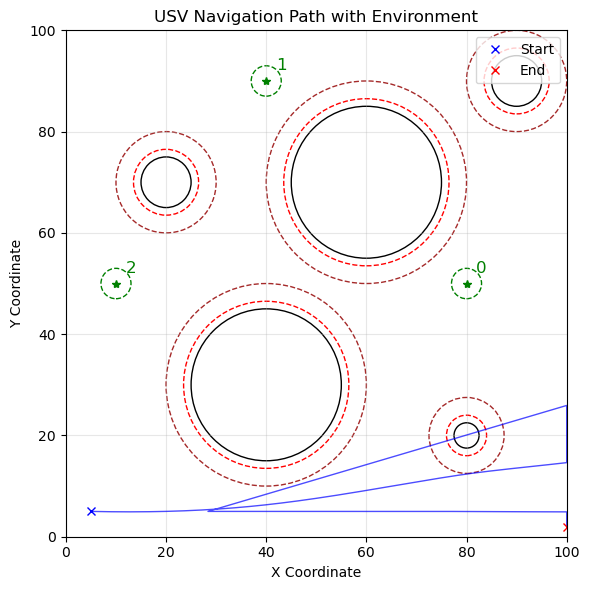

In [7]:
# 创建测试环境（使用与训练相同的环境参数）
from stable_baselines3 import TD3
import gymnasium as gym
import matplotlib.pyplot as plt
from my_USV_Env import MAX, MyUsvEnv_Gym
model = TD3.load("td3_MyUsvEnv")

# Register the environment so we can create it with gym.make()
gym.register(
    id="myenv/MyUsvEnv_Gym-v0",
    entry_point=MyUsvEnv_Gym,
)
env = gym.make("myenv/MyUsvEnv_Gym-v0")
env.unwrapped.__init__(record_flag=True) 
obs, info = env.reset()  # 新版Gym返回元组
terminated = False
truncated = False
total_reward = 0

while not (terminated or truncated):
    action, _ = model.predict(obs, deterministic=True)  # 确保传入的是numpy数组
    # 新版Gym返回5个值
    obs, reward, terminated, truncated, info = env.step(action)
    total_reward += reward
    points=(float(obs["x_norm"]*MAX),float(obs["y_norm"]*MAX))
    # env.record_points(points)
    env.unwrapped.record_points(points,csv_file="usv_path_points_1.csv")
print(total_reward)    
env.unwrapped.draw_path("usv_path_points_1.csv")


